In [1]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [2]:
def parse_osu_file(filepath, n_test):
    data = []
    with open(filepath, 'r') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    size = int(parts[0])
                    val = float(parts[1])
                    data.append((size, val))
                except ValueError:
                    continue
    df = pd.DataFrame(data, columns=['size', 'val'])
    if not df.empty:
        df["n_test"] = n_test
        df['size'] = pd.to_numeric(df['size'], errors='coerce')
        df['val'] = pd.to_numeric(df['val'], errors='coerce')
        df = df.dropna()
    return df

def aggregate_runs(pattern):
    files = sorted(glob.glob(pattern))
    if not files:
        print(f"Aviso: Nenhum arquivo encontrado para '{pattern}'")
        return None

    dfs = [parse_osu_file(f, i+1) for i, f in enumerate(files) if os.path.exists(f) and os.path.getsize(f) > 0]
    dfs = [df for df in dfs if not df.empty]
    
    if not dfs:
        print(f"Aviso: Sem dados numéricos válidos para '{pattern}'")
        return None

    merged = pd.concat(dfs, ignore_index=True)
    #grouped = merged.groupby('size')['val'].agg(['mean', 'std']).fillna(0).reset_index()
    return merged

In [3]:
# 1. Carregar logs
RESULTS_DIR="/home/user/data/desafio_osu/resultados_1028096.ada"
native_lat = aggregate_runs(os.path.join(RESULTS_DIR, 'native_latency_run*.log'))
container_lat = aggregate_runs(os.path.join(RESULTS_DIR, 'container_latency_run*.log'))
native_bw = aggregate_runs(os.path.join(RESULTS_DIR, 'native_bw_run*.log'))
container_bw = aggregate_runs(os.path.join(RESULTS_DIR, 'container_bw_run*.log'))

In [4]:
native_lat

,size,val,n_test
0,1,1.85,1
1,2,1.86,1
2,4,1.85,1
3,8,1.84,1
4,16,1.86,1
...,...,...,...
685,262144,27.55,30
686,524288,48.93,30
687,1048576,91.90,30
688,2097152,177.19,30


In [5]:
native_lat.columns

Index(['size', 'val', 'n_test'], dtype='str')

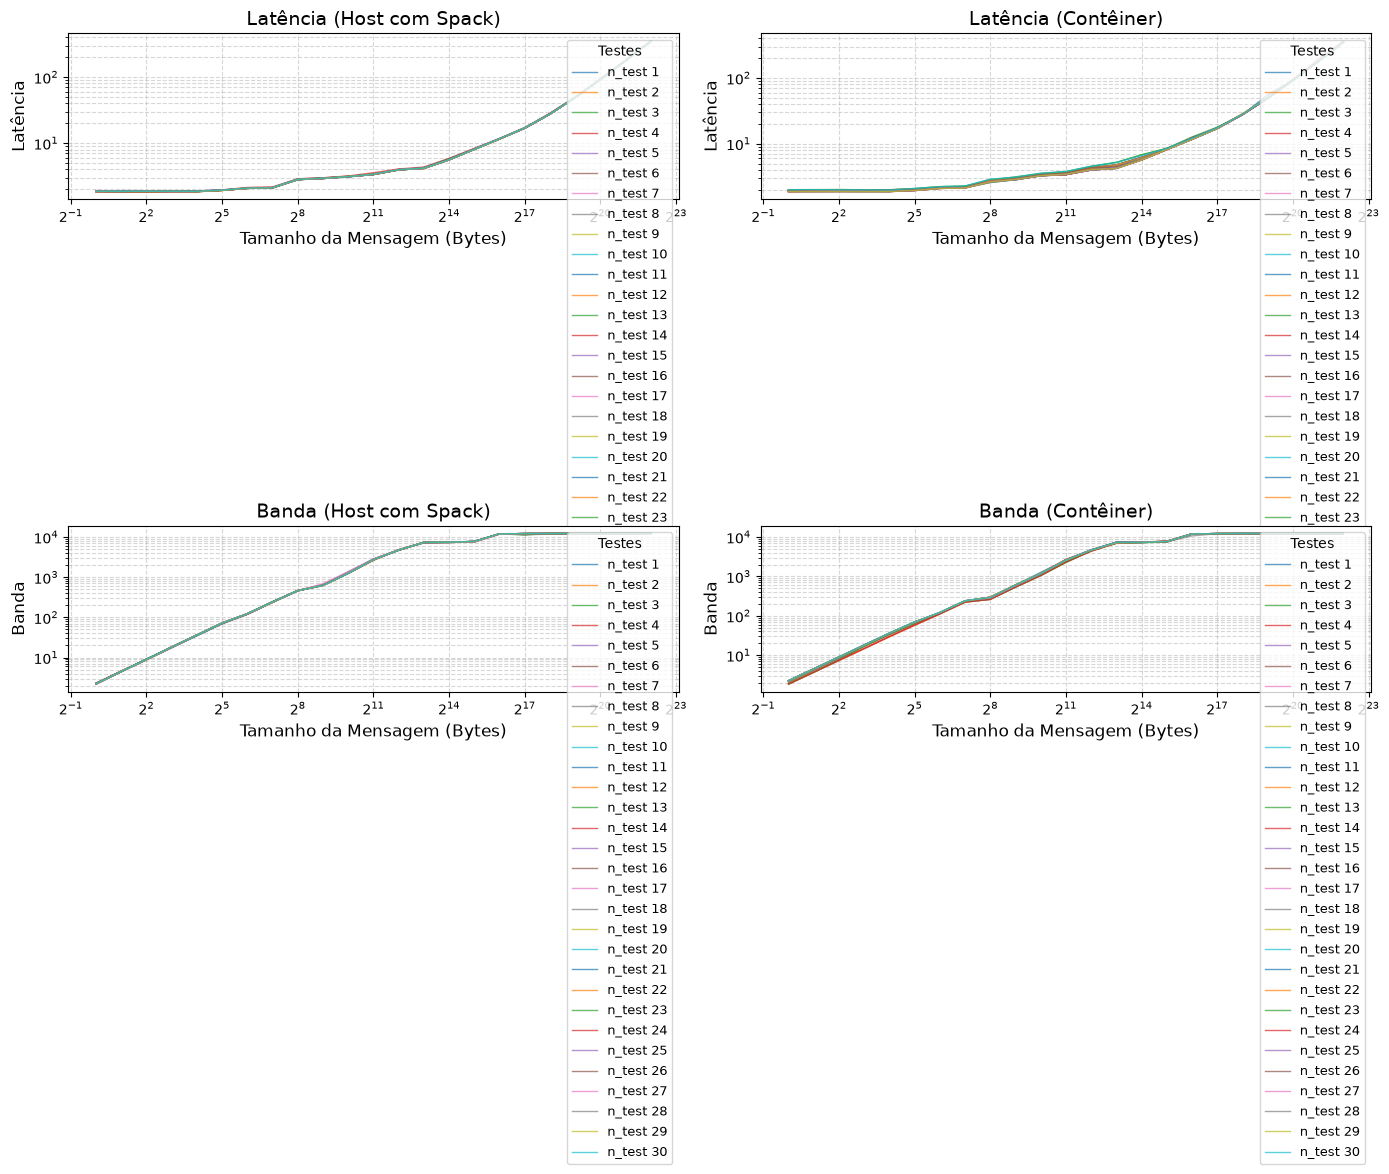

In [6]:


# Definindo os dados a serem ploteados (assumindo que 'native_lat' etc já existem no seu ambiente)
variables = {
    'Latência (Host com Spack)': native_lat,
    'Latência (Contêiner)': container_lat,
    'Banda (Host com Spack)': native_bw,
    'Banda (Contêiner)': container_bw
}

# Criação do layout 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (title, df) in enumerate(variables.items()):
    ax = axes[i]
    
    # Verifica se o dataframe existe e não está vazio
    if df is None or df.empty:
        continue
        
    # Itera sobre cada 'n_test' para criar uma linha individual
    # O groupby garante que pegamos apenas as linhas do mesmo teste juntos
    for name, group in df.groupby('n_test'):
        group_sorted = group.sort_values('size')
        
        # Plota a linha com o label contendo o número do n_test
        ax.plot(group_sorted['size'], group_sorted['val'], 
                label=f'n_test {name}', alpha=0.7, linewidth=1)

    # Escalas Logarítmicas (preservando seu visual original)
    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    
    # Labels e Título
    ax.set_xlabel('Tamanho da Mensagem (Bytes)', fontsize=12)
    ax.set_ylabel(title.split(' (')[0], fontsize=12)
    ax.set_title(title, fontsize=14)
    
    # Grade estilo "dashed" e transparente
    ax.grid(True, which="both", ls="--", alpha=0.5)
    
    # ADICIONADO: Exibindo a legenda com os tipos de n_test para este gráfico específico
    handles, labels = ax.get_legend_handles_labels()
    if len(labels) > 0:
        # Limita visualmente se houver muitos testes (ex: mostra apenas os primeiros 50 para evitar poluição total)
        max_items = min(len(labels), 50)
        ax.legend(handles[:max_items], labels[:max_items], title='Testes', loc='best', fontsize=9)

plt.tight_layout()
plt.savefig('graficos_raw_com_legenda.png', dpi=300, bbox_inches='tight')
plt.show()

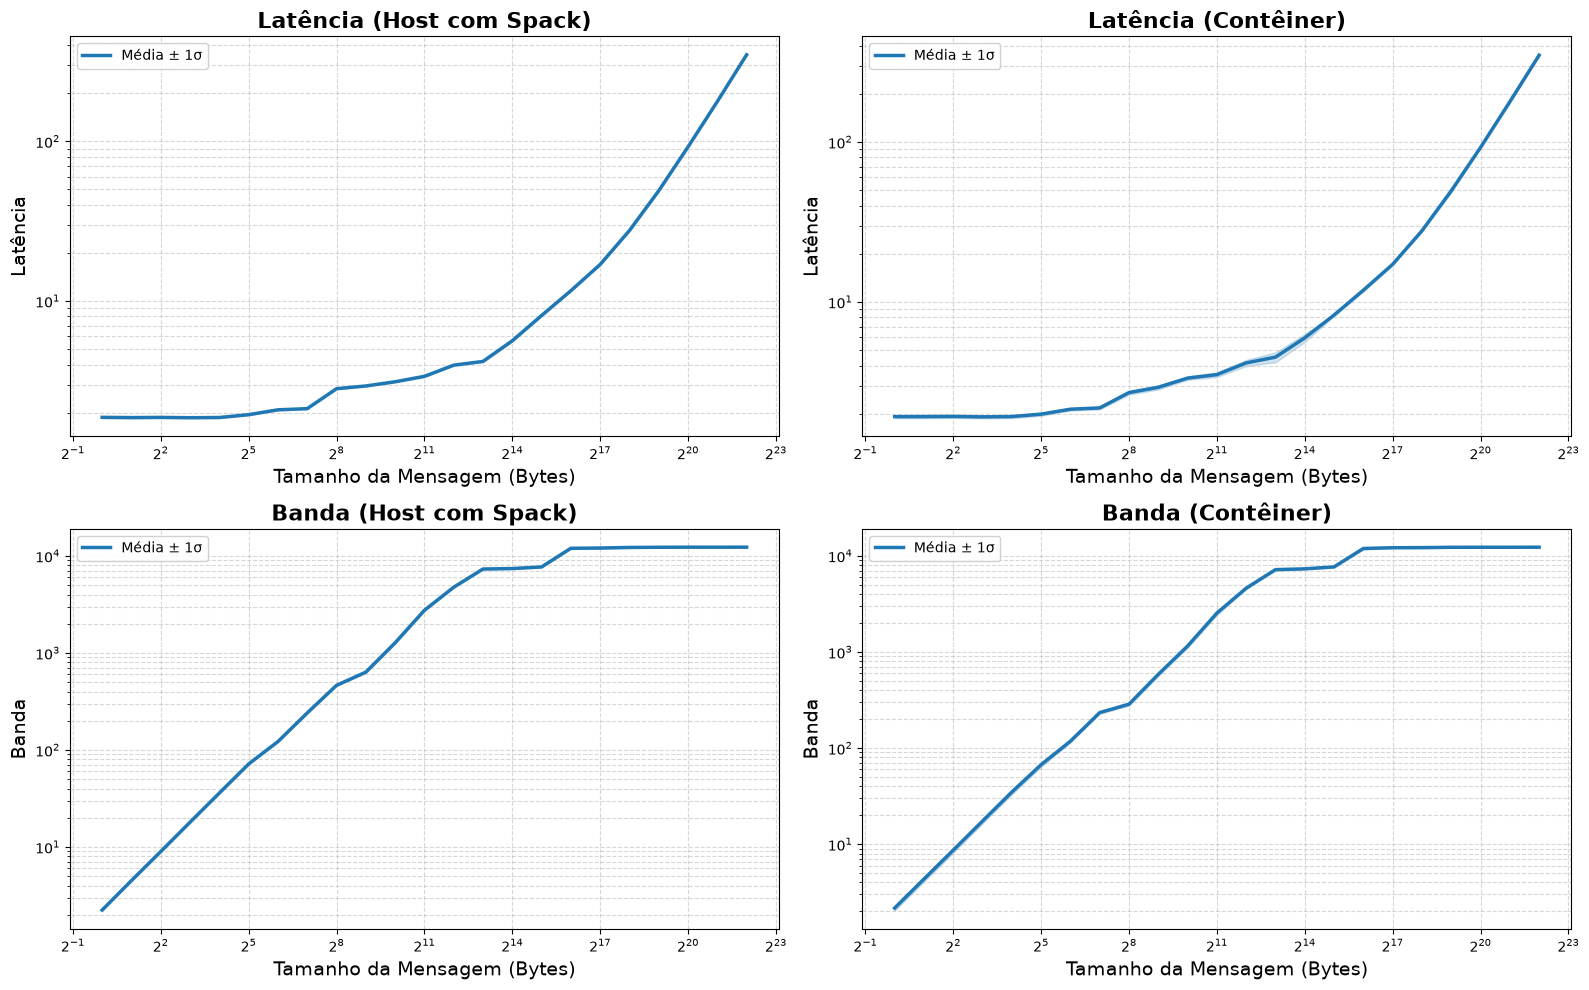

In [7]:


# Dicionário com os seus dataframes (mantido do exemplo anterior)
variables = {
    'Latência (Host com Spack)': native_lat,
    'Latência (Contêiner)': container_lat,
    'Banda (Host com Spack)': native_bw,
    'Banda (Contêiner)': container_bw
}

# Criação do layout 2x2 (Subplots) para comparar cada cenário individualmente agregado
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (title, df) in enumerate(variables.items()):
    ax = axes[i]

    if df is None or df.empty:
        continue

    # ---------------------------------------------------------
    # Lógica Seaborn: Agrupamento Automático por 'size'
    # ---------------------------------------------------------
    sns.lineplot(
        data=df, 
        x='size',           # O agrupamento é feito aqui automaticamente
        y='val',            # Pega o valor Y para cada X
        ax=ax, 
        errorbar='sd',            # 'Margin of Error' definida como Desvio Padrão (Standard Deviation)
        linewidth=2.5,      # Espessura da linha de tendência (média)
        label='Média ± 1σ'  # Legenda única para este gráfico
    )

    # Aplicação das escalas Logarítmicas (Estilo do seu exemplo original)
    ax.set_xscale('log', base=2)
    ax.set_yscale('log')

    # Configuração de Títulos e Labels
    ax.set_xlabel('Tamanho da Mensagem (Bytes)', fontsize=14)
    
    # Pega apenas a primeira parte do título para o eixo Y (ex: "Latência")
    y_label = title.split('(')[0].strip() 
    ax.set_ylabel(y_label, fontsize=14)
    
    ax.set_title(title, fontsize=16, fontweight='bold')

    # Grade tracejada transparente
    ax.grid(True, which="both", ls="--", alpha=0.5)

    # Posiciona a legenda
    ax.legend(loc='best', framealpha=0.9)

plt.tight_layout()
plt.savefig('graficos_agregados_seaborn.png', dpi=300, bbox_inches='tight')
plt.show()

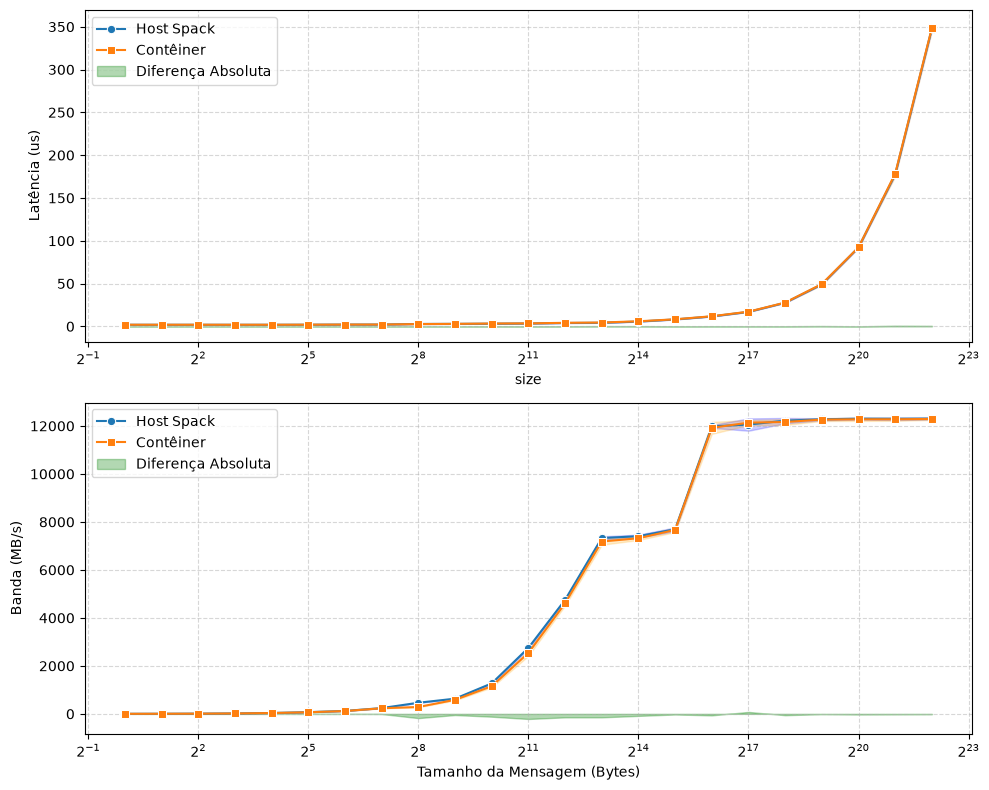

In [8]:


# Função auxiliar para calcular estatísticas (Média e Desvio Padrão)
def get_stats(df):
    stats = df.groupby('size')['val'].agg(['mean', 'std']).reset_index()
    return stats.rename(columns={'mean': 'y_mean', 'std': 'y_std'})

# Preparação dos dados de Latência
lat_n = get_stats(native_lat).rename(columns={'y_mean': 'lat_n_mean', 'y_std': 'lat_n_std'})
lat_c = get_stats(container_lat).rename(columns={'y_mean': 'lat_c_mean', 'y_std': 'lat_c_std'})
lat_data = pd.merge(lat_n, lat_c, on='size').sort_values('size')

# Preparação dos dados de Banda (BW)
bw_n = get_stats(native_bw).rename(columns={'y_mean': 'bw_n_mean', 'y_std': 'bw_n_std'})
bw_c = get_stats(container_bw).rename(columns={'y_mean': 'bw_c_mean', 'y_std': 'bw_c_std'})
bw_data = pd.merge(bw_n, bw_c, on='size').sort_values('size')

# --- Cálculo do Delta (Diferença) para visualizar a pequena margem ---
lat_data['delta'] = lat_data['lat_c_mean'] - lat_data['lat_n_mean']
# Propagação de erro padrão: sqrt(var_n + var_c)
lat_data['err_delta'] = np.sqrt(lat_data['lat_n_std']**2 + lat_data['lat_c_std']**2)

bw_data['delta'] = bw_data['bw_c_mean'] - bw_data['bw_n_mean']
bw_data['err_delta'] = np.sqrt(bw_data['bw_n_std']**2 + bw_data['bw_c_std']**2)


# --- Plotagem ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# 1. Gráfico de Latência (Sobreposição + Delta)
sns.lineplot(data=lat_data, x='size', y='lat_n_mean', ax=ax1, label='Host Spack', marker='o')
sns.lineplot(data=lat_data, x='size', y='lat_c_mean', ax=ax1, label='Contêiner', marker='s')

# Preenchimento das margens de erro (Ribbon) para Latência
ax1.fill_between(lat_data['size'], lat_data['lat_n_mean'] - lat_data['lat_n_std'], 
                 lat_data['lat_n_mean'] + lat_data['lat_n_std'], alpha=0.2, color='blue')
ax1.fill_between(lat_data['size'], lat_data['lat_c_mean'] - lat_data['lat_c_std'], 
                 lat_data['lat_c_mean'] + lat_data['lat_c_std'], alpha=0.2, color='orange')

# Gráfico do Delta de Latência (Segundo eixo abaixo)
ax1.fill_between(lat_data['size'], 0, lat_data['delta'], alpha=0.3, color='green', label='Diferença Absoluta')
ax1.set_ylabel('Latência (us)')
ax1.legend(loc='best')
ax1.grid(True, which="both", ls="--", alpha=0.5)

# 2. Gráfico de Banda (Sobreposição + Delta)
sns.lineplot(data=bw_data, x='size', y='bw_n_mean', ax=ax2, label='Host Spack', marker='o')
sns.lineplot(data=bw_data, x='size', y='bw_c_mean', ax=ax2, label='Contêiner', marker='s')

# Preenchimento das margens de erro (Ribbon) para Banda
ax2.fill_between(bw_data['size'], bw_data['bw_n_mean'] - bw_data['bw_n_std'], 
                 bw_data['bw_n_mean'] + bw_data['bw_n_std'], alpha=0.2, color='blue')
ax2.fill_between(bw_data['size'], bw_data['bw_c_mean'] - bw_data['bw_c_std'], 
                 bw_data['bw_c_mean'] + bw_data['bw_c_std'], alpha=0.2, color='orange')

# Gráfico do Delta de Banda
ax2.fill_between(bw_data['size'], 0, bw_data['delta'], alpha=0.3, color='green', label='Diferença Absoluta')
ax2.set_xlabel('Tamanho da Mensagem (Bytes)')
ax2.set_ylabel('Banda (MB/s)')
ax2.legend(loc='best')
ax2.grid(True, which="both", ls="--", alpha=0.5)

# Configurações Logarítmicas para os eixos X (Tamanho)
for ax in [ax1, ax2]:
    ax.set_xscale('log', base=2)
    
plt.tight_layout()
plt.savefig('graficos_diferenca_fina.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:


# ==============================================================================
# DOCUMENTAÇÃO METODOLÓGICA E ESTATÍSTICA
# ==============================================================================
# MÉTODOS UTILIZADOS:
# 1. Teste Não-Paramétrico de Mann-Whitney U (stats.mannwhitneyu):
#    - Justificativa: Dados de latência violam a premissa de normalidade (assimetria à direita)
#      e possuem sensibilidade a outliers de cauda (tail latency). O teste compara a ordem 
#      dos postos (ranks) em vez das médias amostrais.
#    - H0 (Hipótese Nula): P(Nativo > Contêiner) = 0.5 (Distribuições idênticas).
#    - H1 (Hipótese Alternativa): P(Nativo > Contêiner) != 0.5 (Distribuições distintas).
#
# 2. Correção de Múltiplos Testes por Benjamini-Hochberg (FDR):
#    - Justificativa: A execução de 23 testes independentes eleva a taxa de erro da família 
#      (FWER). A correção controla a Taxa de Descoberta Falsa (FDR) com alfa = 0.05.
# ==============================================================================

# 1. Preparação e unificação dos dados
df_n = native_lat.assign(group='Nativo').astype({'val': float})
df_c = container_lat.assign(group='Contêiner').astype({'val': float})
df_combined = pd.concat([df_n, df_c], ignore_index=True)

results = []

for size in sorted(df_combined['size'].unique()):
    subset = df_combined[df_combined['size'] == size]
    
    native_vals = subset.loc[subset['group'] == 'Nativo', 'val'].values
    container_vals = subset.loc[subset['group'] == 'Contêiner', 'val'].values
    
    if len(native_vals) < 2 or len(container_vals) < 2:
        continue

    # Métricas descritivas de posição
    mean_nat = native_vals.mean()
    mean_ctn = container_vals.mean()
    diff_us = mean_ctn - mean_nat  # Valor positivo = Contêiner mais lento
    overhead_pct = (diff_us / mean_nat) * 100

    # Teste não-paramétrico bilateral de Mann-Whitney U
    stat_u, p_mw = stats.mannwhitneyu(native_vals, container_vals, alternative='two-sided')

    results.append({
        'Tamanho': size,
        'Nativo (us)': mean_nat,
        'Contêiner (us)': mean_ctn,
        'Diferença (us)': diff_us,
        'Overhead (%)': overhead_pct,
        'p_value': p_mw
    })

df_res = pd.DataFrame(results)

# 2. Correção para múltiplos testes de hipótese (Benjamini-Hochberg FDR)
_, df_res['p_adj'], _, _ = multipletests(df_res['p_value'], method='fdr_bh')

# 3. Classificação das conclusões com base no p-valor ajustado (alfa = 0.05)
def classificar_resultado(row):
    if row['p_adj'] >= 0.05:
        return "Equivalentes"
    elif row['Diferença (us)'] > 0:
        return "Nativo mais rápido"
    else:
        return "Contêiner mais rápido (Anomalia)"

df_res['Resultado'] = df_res.apply(classificar_resultado, axis=1)

# 4. Formatação tabular legível
df_display = pd.DataFrame({
    'Tamanho': df_res['Tamanho'].apply(
        lambda x: f"{x} B" if x < 1024 else f"{x//1024} KB" if x < 1048576 else f"{x//1048576} MB"
    ),
    'Nativo': df_res['Nativo (us)'].map('{:.3f} us'.format),
    'Contêiner': df_res['Contêiner (us)'].map('{:.3f} us'.format),
    'Diferença': df_res['Diferença (us)'].map('{:+.3f} us'.format),
    'Overhead': df_res['Overhead (%)'].map('{:+.2f}%'.format),
    'P-Valor Adj.': df_res['p_adj'].apply(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"),
    'Resultado': df_res['Resultado']
})

print(df_display.to_string(index=False))

Tamanho     Nativo  Contêiner Diferença Overhead P-Valor Adj.                        Resultado
    1 B   1.869 us   1.917 us +0.048 us   +2.55%      < 0.001               Nativo mais rápido
    2 B   1.862 us   1.918 us +0.056 us   +2.99%      < 0.001               Nativo mais rápido
    4 B   1.867 us   1.922 us +0.055 us   +2.93%      < 0.001               Nativo mais rápido
    8 B   1.859 us   1.910 us +0.051 us   +2.76%      < 0.001               Nativo mais rápido
   16 B   1.865 us   1.918 us +0.054 us   +2.88%      < 0.001               Nativo mais rápido
   32 B   1.942 us   1.986 us +0.045 us   +2.30%      < 0.001               Nativo mais rápido
   64 B   2.083 us   2.133 us +0.050 us   +2.38%      < 0.001               Nativo mais rápido
  128 B   2.119 us   2.173 us +0.054 us   +2.55%      < 0.001               Nativo mais rápido
  256 B   2.825 us   2.709 us -0.116 us   -4.12%      < 0.001 Contêiner mais rápido (Anomalia)
  512 B   2.937 us   2.924 us -0.014 us   -0.47%  